# Sistem Rekomendasi: Matrix Factorization (Funk SVD & NMF)

**Matrix Factorization** menebak _rating_ film yang belum ditonton dengan memecah satu tabel _rating_ besar ($R$) menjadi perkalian dua tabel faktor laten berdimensi jauh lebih kecil: **Tabel Selera Pengguna** dan **Tabel Ciri Khas Film**.

---

### 1. Apa itu _Latent Factor_ (Faktor Laten)?

**Faktor Laten** adalah "ciri khas tersembunyi" yang ditemukan sendiri oleh komputer dari pola angka _rating_, tanpa diberi tahu genre filmnya (misalnya: Faktor 1 = _seberapa banyak adegan aksi_, Faktor 2 = _seberapa lucu filmnya_).

---

### 2. Algoritma A: Funk SVD (Stochastic Gradient Descent)

**Funk SVD** (_Regularized Matrix Factorization with Stochastic Gradient Descent_) adalah algoritma yang dipopulerkan oleh Simon Funk pada kompetisi Netflix Prize. Berbeda dengan SVD matematika klasik yang menganggap kotak kosong (`0`) sebagai _rating_ buruk, **Funk SVD hanya belajar dari _rating_ yang sudah terisi saja** ($R_{u,i} > 0$).

#### A. Rumus Prediksi Rating

Untuk menebak skor _rating_ pengguna $u$ pada film $i$, kita mengalikan kecocokan selera pengguna tersebut ($P$) dengan ciri khas filmnya ($Q$):

$$\hat{r}_{u,i} = \sum_{k=1}^{K} P_{u,k} \cdot Q_{i,k}$$

- **Arti Tiap Simbol (Bahasa Sehari-hari):**
  - $u$ (**User**): Urutan baris pengguna (misalnya: baris ke-0 adalah `User_A`).
  - $i$ (**Item**): Urutan kolom film (misalnya: kolom ke-2 adalah `Gundala`).
  - $K$ (**Jumlah Faktor Laten**): Banyaknya ciri tersembunyi yang kita tentukan (misalnya $K = 2$ ciri).
  - $k$: Urutan ciri ke-1 sampai ke-$K$.
  - $P_{u,k}$: Angka seberapa suka pengguna $u$ pada ciri ke-$k$.
  - $Q_{i,k}$: Angka seberapa kuat film $i$ memiliki ciri ke-$k$.
  - $\sum_{k=1}^{K}$ (**Sigma / Penjumlahan**): Kalikan setiap pasang $P_{u,k} \cdot Q_{i,k}$, lalu **jumlahkan semuanya**.
  - $\hat{r}_{u,i}$ (**R-topi**): Angka tebakan (_prediksi_) skor _rating_ dari komputer.
- **Contoh Hitungan Manual ($K = 2$ ciri):**
  - Selera **User_A**: $P_A = [0.9, 0.2]$ _(90% suka aksi, 20% suka komedi)_
  - Ciri **Film X**: $Q_X = [4.5, 1.0]$ _(sangat penuh aksi, sedikit komedi)_
  - **Tebakan Rating**: $\hat{r}_{A,X} = (0.9 \times 4.5) + (0.2 \times 1.0) = 4.05 + 0.20 = \mathbf{4.25}$

#### B. Rumus Belajar dari Kesalahan (_SGD_ & _Regularization_)

Awalnya, komputer mengisi tabel $P$ dan $Q$ dengan angka acak, lalu memperbaikinya berulang kali (_epoch_) berdasarkan selisih kesalahan (_error_):

$$e_{u,i} = R_{u,i} - \hat{r}_{u,i}$$

$$P_{u,k} \leftarrow P_{u,k} + \alpha \cdot (2 \cdot e_{u,i} \cdot Q_{i,k} - \beta \cdot P_{u,k})$$
$$Q_{i,k} \leftarrow Q_{i,k} + \alpha \cdot (2 \cdot e_{u,i} \cdot P_{u,k} - \beta \cdot Q_{i,k})$$

- **Arti Tiap Simbol:**
  - $R_{u,i}$: _Rating_ asli yang diberikan pengguna $u$ pada film $i$.
  - $e_{u,i}$ (**Error**): Selisih _rating_ asli dikurangi tebakan komputer ($R_{u,i} - \hat{r}_{u,i}$). Jika asli `5.0` dan tebakan `4.2`, maka $e = +0.8$ (tebakan kurang tinggi).
  - $\leftarrow$ (**Panah Pembaruan**): Artinya "ganti nilai lama dengan nilai baru di sebelah kanan".
  - $\alpha$ (**Alpha / _Learning Rate_**): Kecepatan belajar komputer (angka kecil seperti `0.01` agar perbaikan nilai tidak kebablasan).
  - $\beta$ (**Beta / _Regularization_**): Rem pengaman (angka kecil seperti `0.02`) agar angka di tabel $P$ dan $Q$ tidak membengkak terlalu besar (_overfitting_).

#### C. Kelebihan & Kekurangan Funk SVD

- **Kelebihan (Pros):**
  - **Mengabaikan Data Kosong:** Hanya melatih model pada _rating_ yang benar-benar ada, sehingga jauh lebih akurat dibandingkan SVD standar.
  - **Menemukan Pola Tersembunyi:** Mampu menebak selera pengguna meski dua pengguna belum pernah menonton film yang sama persis.
  - **Hemat Memori:** Tabel raksasa yang jarang terisi (_sparse_) dipadatkan menjadi dua tabel kecil ($P$ dan $Q$).
- **Kekurangan (Cons):**
  - **Sulit Dijelaskan ke Pengguna:** Komputer hanya menghasilkan angka faktor abstrak (`Factor_0`, `Factor_1`) yang bisa bernilai negatif, sehingga maknanya sulit dibaca manusia.
  - **Memerlukan _Tuning_ Parameter:** Akurasi bergantung pada pemilihan nilai $\alpha$ (_learning rate_), $\beta$ (_regularization_), dan jumlah _epoch_.
  - **Masalah _Cold-Start_:** Tidak bisa langsung menebak pengguna baru atau film baru yang belum memiliki riwayat _rating_.

---

### 3. Algoritma B: NMF (Non-Negative Matrix Factorization)

**NMF** adalah teknik memecah tabel _rating_ ($R$) menjadi dua tabel faktor yang **seluruh angkanya wajib positif** ($0$ atau lebih, tidak boleh minus).

- **Mengapa tidak boleh ada angka negatif?**
  Bayangkan sebuah film sebagai campuran resep masakan. Masuk akal jika sebuah film memiliki komposisi _"70% Aksi dan 30% Komedi"_, tetapi tidak masuk akal jika disebut _"-40% Komedi"_. Karena semua angka positif, hasil pemecahan tabel NMF sangat mudah dibaca sebagai **porsi atau bobot kontribusi fitur**.

#### A. Rumus Prediksi & Pembaruan Perkalian (_Multiplicative Updates_)

Untuk memprediksi _rating_, NMF mengalikan **Tabel Porsi Selera Pengguna ($W$)** dengan **Tabel Porsi Ciri Film ($H$)**:
$$\hat{R} = W \times H$$

Agar tebakan $\hat{R}$ mendekati _rating_ asli $R$ tanpa pernah menghasilkan angka minus, NMF tidak menggunakan pengurangan (seperti pada Funk SVD), melainkan **mengalikan nilai lama dengan rasio perbandingan**:

$$H \leftarrow H \odot \frac{W^T R}{W^T W H + \epsilon} \qquad \text{dan} \qquad W \leftarrow W \odot \frac{R H^T}{W H H^T + \epsilon}$$

- **Logika Sederhana di Balik Pecahan $\frac{\text{Atas}}{\text{Bawah}}$:**

  - **Bagian Atas ($W^T R$ atau $R H^T$):** Mewakili ukuran **target _rating_ asli** yang ingin dicapai.
  - **Bagian Bawah ($W^T W H$ atau $W H H^T$):** Mewakili ukuran **tebakan model saat ini** ($\hat{R}$).
  - **Cara Kerjanya:**
    - Jika tebakan masih **terlalu kecil** dibanding aslinya, nilai pecahan $\frac{\text{Atas}}{\text{Bawah}} > 1$, sehingga nilai faktor dikalikan angka $> 1$ (**nilai naik**).
    - Jika tebakan **terlalu besar**, nilai pecahan $\frac{\text{Atas}}{\text{Bawah}} < 1$, sehingga nilai faktor dikalikan angka $< 1$ (**nilai turun**).
    - Jika tebakan sudah **pas**, nilai pecahan $= 1$, sehingga nilai faktor **berhenti berubah** (konvergen).

- **Arti Tiap Simbol:**

  - $R$: Tabel _rating_ asli berukuran $M \times N$ ($M$ pengguna, $N$ film).
  - $\hat{R}$: Tabel tebakan _rating_ hasil perkalian $W \times H$.
  - $W$: Tabel porsi selera pengguna terhadap tiap faktor laten (ukuran $M \times K$, semua angka $\ge 0$).
  - $H$: Tabel porsi ciri film pada tiap faktor laten (ukuran $K \times N$, semua angka $\ge 0$).
  - $W^T, H^T$: Matriks transpos (menukar baris menjadi kolom agar ukuran matriks cocok saat dikalikan).
  - $\odot$: Perkalian posisi yang sama (_element-wise_), yaitu mengalikan angka di baris dan kolom yang persis sama.
  - $\epsilon$ (**Epsilon**): Angka sangat kecil (`1e-9` atau `0.000000001`) yang ditambahkan di bagian bawah agar komputer tidak error akibat pembagian dengan angka `0`.

- **Contoh Hitungan Manual Lengkap ($K = 2$ faktor: Aksi & Komedi):**

  1. **Menghitung Tebakan Rating ($\hat{R} = W \times H$):**
     - Porsi selera **User_A**: $W_A = [0.8, 0.2]$ _(80% suka aksi, 20% suka komedi)_
     - Porsi ciri **Film X**: $H_X = [4.0, 1.5]^T$ _(skor aksi 4.0, skor komedi 1.5)_
     - **Tebakan Rating**: $\hat{R}_{A,X} = (0.8 \times 4.0) + (0.2 \times 1.5) = 3.2 + 0.3 = \mathbf{3.5}$
  2. **Memperbarui Bobot ($H \leftarrow H \odot \frac{W^T R}{W^T \hat{R}}$):**
     - Misalkan **Film X** dinilai oleh 3 penonton dengan _rating_ asli lebih tinggi dari tebakan sistem:
     - **User_A** _(selera aksi $0.8$)_: Rating asli $R = 4.5$ vs Tebakan $\hat{R} = 3.5$
     - **User_B** _(selera aksi $1.0$)_: Rating asli $R = 5.0$ vs Tebakan $\hat{R} = 4.0$
     - **User_C** _(selera aksi $0.8$)_: Rating asli $R = 8.0$ vs Tebakan $\hat{R} = 6.5$
     - **Menghitung Bagian Atas ($W_{\text{aksi}}^T \cdot R$ — Total Target):**
       $$\text{Bagian Atas} = (0.8 \times 4.5) + (1.0 \times 5.0) + (0.8 \times 8.0) = 3.6 + 5.0 + 6.4 = \mathbf{15.0}$$
     - **Menghitung Bagian Bawah ($W_{\text{aksi}}^T \cdot \hat{R}$ — Total Tebakan):**
       $$\text{Bagian Bawah} = (0.8 \times 3.5) + (1.0 \times 4.0) + (0.8 \times 6.5) = 2.8 + 4.0 + 5.2 = \mathbf{12.0}$$
     - **Rasio Pembaruan:** $\frac{15.0}{12.0} = \mathbf{1.25}$
     - **Bobot Baru:** $H_{\text{aksi}} \leftarrow 4.0 \times 1.25 = \mathbf{5.0}$ _(bobot otomatis naik mendekati target tanpa pernah menyentuh angka negatif)_.

#### B. Kelebihan & Kekurangan NMF

- **Kelebihan (Pros):**
  - **Mudah Dipahami Manusia:** Karena semua angka bernilai positif, setiap faktor dapat dibaca langsung sebagai persentase atau porsi kontribusi fitur.
  - **Tanpa _Learning Rate_:** Tidak perlu repot mengatur kecepatan belajar ($\alpha$) seperti pada Funk SVD karena rasio pecahan otomatis menyesuaikan besar langkah perubahannya.
- **Kekurangan (Cons):**
  - **Menganggap Kotak Kosong sebagai Nilai Nol:** Karena mengalikan seluruh tabel $R$ secara bersamaan, film yang belum ditonton (`0`) ikut dihitung sebagai _rating_ `0`, sehingga hasil prediksi skornya cenderung lebih rendah dari skala asli `1–5`.
  - **Tidak Bisa Menerima Angka Negatif:** Tidak dapat digunakan jika data sudah dinormalisasi dengan pengurangan rata-rata (_mean-centered_).


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
def createDataset() -> pd.DataFrame:
  '''
  Membuat dataset contoh berisi daftar penilaian pengguna terhadap film.

  Returns:
    pd.DataFrame: Tabel berisi kolom itemId, rating, dan userId.
  '''
  interactionData = {
    'itemId': [
      'The Raid',
      'Headshot',
      'Laskar Pelangi',
      'The Raid',
      'Headshot',
      'Gundala',
      'Laskar Pelangi',
      'Cek Toko Sebelah',
      'Warkop DKI Reborn',
      'The Raid',
      'Gundala',
      'Cek Toko Sebelah',
      'Warkop DKI Reborn',
      'Laskar Pelangi',
    ],
    'rating': [
      5.0,
      4.5,
      1.0,
      4.5,
      5.0,
      4.0,
      5.0,
      4.5,
      4.0,
      1.5,
      2.0,
      5.0,
      4.5,
      4.5,
    ],
    'userId': [
      'User_A',
      'User_A',
      'User_A',
      'User_B',
      'User_B',
      'User_B',
      'User_C',
      'User_C',
      'User_C',
      'User_D',
      'User_D',
      'User_D',
      'User_E',
      'User_E',
    ],
  }
  return pd.DataFrame(interactionData)

def getRecommendations(
  predictedMatrix: pd.DataFrame,
  ratingMatrix: pd.DataFrame,
  targetUser: str,
  topN: int,
) -> pd.DataFrame:
  '''
  Mengambil daftar rekomendasi film terbaik yang belum ditonton oleh pengguna target.

  Args:
    predictedMatrix (pd.DataFrame): Tabel hasil tebakan rating (R_hat).
    ratingMatrix (pd.DataFrame): Tabel rating asli (0.0 berarti belum ditonton).
    targetUser (str): Nama pengguna yang ingin diberi rekomendasi.
    topN (int): Jumlah film rekomendasi yang diinginkan.

  Returns:
    pd.DataFrame: Tabel berisi itemId dan predictedRating tertinggi.
  '''
  resultFrame = pd.DataFrame()
  unwatchedMask = ratingMatrix.loc[targetUser] == 0
  userPredictions = predictedMatrix.loc[targetUser, unwatchedMask]

  # Mengurutkan tebakan skor dari tertinggi ke terendah untuk film yang belum ditonton
  resultFrame = (
    userPredictions.sort_values(ascending=False)
    .head(topN)
    .reset_index()
    .rename(columns={targetUser: 'predictedRating'})
  )
  resultFrame['predictedRating'] = resultFrame['predictedRating'].round(4)
  return resultFrame

def plotFactorizationComparison(
  funkPredictions: pd.DataFrame,
  funkRecommendations: pd.DataFrame,
  nmfPredictions: pd.DataFrame,
  nmfRecommendations: pd.DataFrame,
  targetUser: str,
) -> None:
  '''
  Menampilkan grafik perbandingan 2x2 antara hasil Funk SVD dan NMF.

  Args:
    funkPredictions (pd.DataFrame): Matriks prediksi lengkap dari Funk SVD.
    funkRecommendations (pd.DataFrame): Tabel rekomendasi teratas dari Funk SVD.
    nmfPredictions (pd.DataFrame): Matriks prediksi lengkap dari NMF.
    nmfRecommendations (pd.DataFrame): Tabel rekomendasi teratas dari NMF.
    targetUser (str): Nama pengguna target rekomendasi.
  '''
  axes = None
  fig = None

  sns.set_theme(style='whitegrid')
  fig, axes = plt.subplots(2, 2, figsize=(15, 10))
  fig.suptitle(
    f"Matrix Factorization Comparison (Funk SVD vs NMF) for '{targetUser}'",
    fontsize=15,
    fontweight='bold',
    y=1.02,
  )

  # 1. Heatmap tebakan rating Funk SVD -> indeks [0, 0]
  sns.heatmap(
    annot=True,
    ax=axes[0, 0],
    cmap='YlGnBu',
    data=funkPredictions,
    fmt='.2f',
  )
  axes[0, 0].set_title('A. Funk SVD Predicted Matrix (R_hat)', fontweight='bold')
  axes[0, 0].tick_params(axis='x', rotation=30)

  # 2. Heatmap tebakan rating NMF -> indeks [0, 1]
  sns.heatmap(
    annot=True,
    ax=axes[0, 1],
    cmap='YlOrRd',
    data=nmfPredictions,
    fmt='.2f',
  )
  axes[0, 1].set_title('B. NMF Predicted Matrix (W x H)', fontweight='bold')
  axes[0, 1].tick_params(axis='x', rotation=30)

  # 3. Diagram batang rekomendasi Funk SVD -> indeks [1, 0]
  sns.barplot(
    ax=axes[1, 0],
    data=funkRecommendations,
    hue='itemId',
    legend=False,
    palette='Blues_d',
    x='predictedRating',
    y='itemId',
  )
  
  axes[1, 0].set_xlim(0, 5.5)
  axes[1, 0].set_xlabel('Predicted Score')
  axes[1, 0].set_ylabel('Item ID')
  axes[1, 0].set_title(f"C. Top Funk SVD Recommendations for '{targetUser}'", fontweight='bold')
  for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fmt='%.2f', padding=4)

  # 4. Diagram batang rekomendasi NMF -> indeks [1, 1]
  sns.barplot(
    ax=axes[1, 1],
    data=nmfRecommendations,
    hue='itemId',
    legend=False,
    palette='Oranges_d',
    x='predictedRating',
    y='itemId',
  )
  axes[1, 1].set_xlim(0, 5.5)
  axes[1, 1].set_xlabel('Predicted Rating')
  axes[1, 1].set_ylabel('Item ID')
  axes[1, 1].set_title(f"D. Top NMF Recommendations for '{targetUser}'", fontweight='bold')
  for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt='%.2f', padding=4)

  plt.tight_layout()
  plt.show()

def trainFunkSvd(
  alpha: float,
  beta: float,
  epochs: int,
  nFactors: int,
  ratingMatrix: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
  '''
  Melatih model Funk SVD menggunakan Stochastic Gradient Descent (Pure NumPy).

  Args:
    alpha (float): Learning rate (kecepatan belajar komputer).
    beta (float): Koefisien regularisasi untuk mencegah overfitting.
    epochs (int): Jumlah pengulangan latihan.
    nFactors (int): Jumlah faktor laten (K).
    ratingMatrix (pd.DataFrame): Matriks rating Pengguna x Item. Rating 0 atau NaN dianggap sebagai missing value.

  Returns:
    tuple: (predictedFrame, userFactorsFrame, itemFactorsFrame).
  '''
  
  # Mengubah matriks rating menjadi NumPy dan mengambil jumlah pengguna serta item
  rawRatings = ratingMatrix.to_numpy(dtype=np.float64, na_value=np.nan)
  numUsers, numItems = rawRatings.shape
  
  # Mengambil indeks pasangan pengguna-item yang memiliki rating valid (> 0)
  userIndices, itemIndices = np.nonzero(
    np.isfinite(rawRatings) & (rawRatings > 0)
  )
  
  # Memastikan terdapat minimal satu rating valid untuk proses pelatihan
  if len(userIndices) == 0:
    raise ValueError('No valid ratings found')
  
  # Membuat generator angka acak agar hasil inisialisasi dapat direproduksi
  rng = np.random.default_rng(42)
  
  # Menginisialisasi matriks faktor laten P (Pengguna x K) dan Q (Item x K)
  userFactors = rng.normal(scale=1.0 / nFactors, size=(numUsers, nFactors))
  itemFactors = rng.normal(scale=1.0 / nFactors, size=(numItems, nFactors))

  # Melatih model selama sejumlah epoch menggunakan SGD
  for _ in range(epochs):
    # Mengacak urutan rating valid pada setiap epoch
    for idx in rng.permutation(len(userIndices)):
      u = userIndices[idx]
      i = itemIndices[idx]
      
      # Menyalin faktor laten agar kedua pembaruan menggunakan nilai sebelumnya
      userVector = userFactors[u].copy()
      itemVector = itemFactors[i].copy()
      
      # Menyalin faktor laten agar kedua pembaruan menggunakan nilai sebelumnya
      predictedRating = np.dot(userVector, itemVector)
      
      # Menghitung error: e(u,i) = R[u,i] - r_hat(u,i)
      error = rawRatings[u, i] - predictedRating
      
      # Memperbarui faktor pengguna P menggunakan SGD dan regularisasi L2
      userFactors[u] = userVector + alpha * (2 * error * itemVector - beta * userVector)
      
      # Memperbarui faktor item Q menggunakan SGD dan regularisasi L2
      itemFactors[i] = itemVector + alpha * (2 * error * userVector - beta * itemVector)
  
  # Menghitung seluruh prediksi rating menggunakan perkalian matriks: R_hat = P @ Q.T
  predictedArray = userFactors @ itemFactors.T
  
  # Membuat nama kolom untuk setiap faktor laten
  factorColumns = [f'Factor_{k}' for k in range(nFactors)]
  
  # Mengubah hasil prediksi menjadi DataFrame Pengguna x Item
  predictedFrame = pd.DataFrame(
    predictedArray,
    index=ratingMatrix.index,
    columns=ratingMatrix.columns,
  )
  
  # Mengubah matriks P menjadi DataFrame Pengguna x Faktor Laten
  userFactorsFrame = pd.DataFrame(
    userFactors,
    index=ratingMatrix.index,
    columns=factorColumns,
  )
  
  # Mengubah matriks Q menjadi DataFrame Item x Faktor Laten
  itemFactorsFrame = pd.DataFrame(
    itemFactors,
    index=ratingMatrix.columns,
    columns=factorColumns,
  )
  
  # Mengembalikan matriks prediksi, faktor pengguna, dan faktor item
  return predictedFrame, userFactorsFrame, itemFactorsFrame

def trainNmf(
  epochs: int,
  nFactors: int,
  ratingMatrix: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
  '''
  Melatih model Non-Negative Matrix Factorization (NMF) dari nol menggunakan
  Multiplicative Update Rules (Pure NumPy).

  Args:
    epochs (int): Jumlah pengulangan pembaruan matriks.
    nFactors (int): Jumlah faktor laten (K).
    ratingMatrix (pd.DataFrame): Tabel rating asli berukuran Pengguna x Item (R).

  Returns:
    tuple: Berisi (predictedFrame, userWeightsFrame, itemFeaturesFrame).
  '''
  denominatorH = np.array([])
  denominatorW = np.array([])
  epsilon = 1e-9
  factorColumns = [f'Factor_{k}' for k in range(nFactors)]
  itemFeatures = np.array([])
  itemFeaturesFrame = pd.DataFrame()
  numItems = ratingMatrix.shape[1]
  numUsers = ratingMatrix.shape[0]
  numeratorH = np.array([])
  numeratorW = np.array([])
  predictedArray = np.array([])
  predictedFrame = pd.DataFrame()
  rawRatings = ratingMatrix.to_numpy()
  userWeights = np.array([])
  userWeightsFrame = pd.DataFrame()

  # Mengisi matriks W (Pengguna x K) dan H (K x Item) dengan angka acak positif
  np.random.seed(42)
  userWeights = np.random.uniform(low=0.1, high=1.0, size=(numUsers, nFactors))
  itemFeatures = np.random.uniform(low=0.1, high=1.0, size=(nFactors, numItems))

  # Melakukan iterasi Multiplicative Update Rules agar W dan H tetap >= 0
  for _ in range(epochs):
    # Komputasi notasi: H <- H * (W^T R) / (W^T W H + epsilon)
    numeratorH = np.dot(userWeights.T, rawRatings)
    denominatorH = np.dot(np.dot(userWeights.T, userWeights), itemFeatures) + epsilon
    itemFeatures = itemFeatures * (numeratorH / denominatorH)

    # Komputasi notasi: W <- W * (R H^T) / (W H H^T + epsilon)
    numeratorW = np.dot(rawRatings, itemFeatures.T)
    denominatorW = np.dot(userWeights, np.dot(itemFeatures, itemFeatures.T)) + epsilon
    userWeights = userWeights * (numeratorW / denominatorW)

  # Komputasi notasi: R_hat = W x H
  predictedArray = np.dot(userWeights, itemFeatures)

  predictedFrame = pd.DataFrame(
    predictedArray,
    columns=ratingMatrix.columns,
    index=ratingMatrix.index,
  )
  userWeightsFrame = pd.DataFrame(
    userWeights,
    columns=factorColumns,
    index=ratingMatrix.index,
  )
  itemFeaturesFrame = pd.DataFrame(
    itemFeatures.T,
    columns=factorColumns,
    index=ratingMatrix.columns,
  )
  return predictedFrame, userWeightsFrame, itemFeaturesFrame


itemId,Cek Toko Sebelah,Gundala,Headshot,Laskar Pelangi,The Raid,Warkop DKI Reborn
userId,,,,,,
User_A,0.0,0.0,4.5,1.0,5.0,0.0
User_B,0.0,4.0,5.0,0.0,4.5,0.0
User_C,4.5,0.0,0.0,5.0,0.0,4.0
User_D,5.0,2.0,0.0,0.0,1.5,0.0
User_E,0.0,0.0,0.0,4.5,0.0,4.5


,itemId,predictedRating
0,Gundala,4.9068
1,Cek Toko Sebelah,4.2600
2,Warkop DKI Reborn,2.8958


,itemId,predictedRating
0,Gundala,2.1262
1,Cek Toko Sebelah,0.5475
2,Warkop DKI Reborn,0.2027


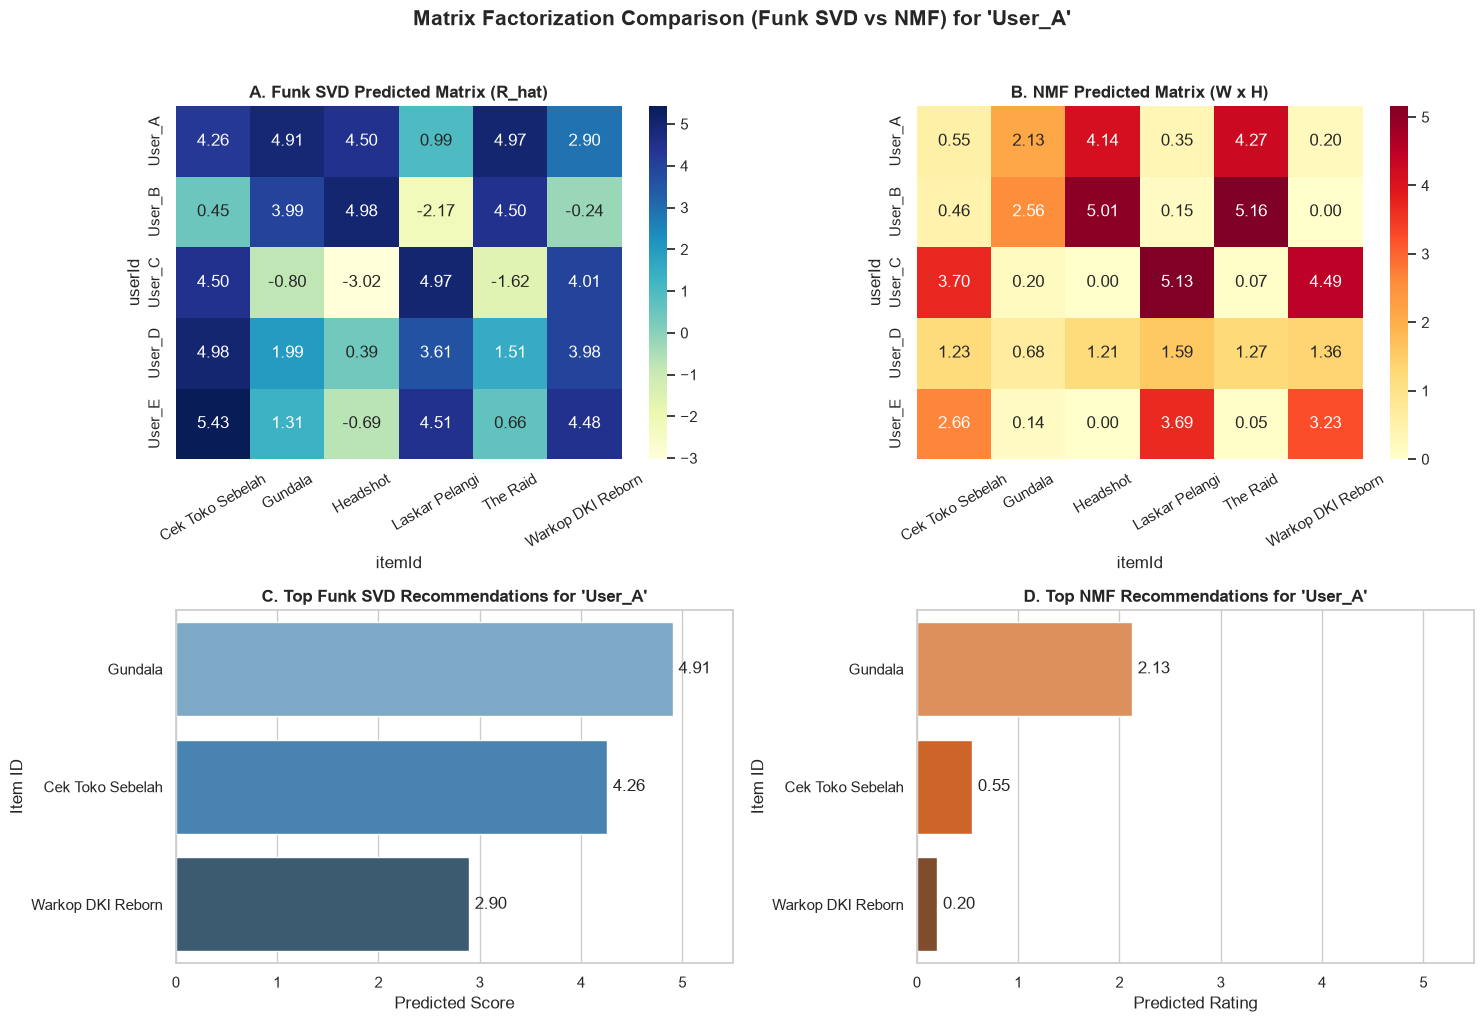

In [3]:
alpha = 0.01
beta = 0.02
epochs = 1000
funkItemFactors = pd.DataFrame()
funkPredictions = pd.DataFrame()
funkRecommendations = pd.DataFrame()
funkUserFactors = pd.DataFrame()
interactionFrame = createDataset()
nFactors = 2
nmfItemFeatures = pd.DataFrame()
nmfPredictions = pd.DataFrame()
nmfRecommendations = pd.DataFrame()
nmfUserWeights = pd.DataFrame()
ratingMatrix = interactionFrame.pivot_table(
  columns='itemId',
  fill_value=0.0,
  index='userId',
  values='rating',
)
targetUser = 'User_A'

# Melatih model Funk SVD dan NMF dari nol
funkPredictions, funkUserFactors, funkItemFactors = trainFunkSvd(
  alpha=alpha,
  beta=beta,
  epochs=epochs,
  nFactors=nFactors,
  ratingMatrix=ratingMatrix,
)
nmfPredictions, nmfUserWeights, nmfItemFeatures = trainNmf(
  epochs=epochs,
  nFactors=nFactors,
  ratingMatrix=ratingMatrix,
)

# Mengambil 3 rekomendasi teratas dari kedua algoritma
funkRecommendations = getRecommendations(
  predictedMatrix=funkPredictions,
  ratingMatrix=ratingMatrix,
  targetUser=targetUser,
  topN=3,
)
nmfRecommendations = getRecommendations(
  predictedMatrix=nmfPredictions,
  ratingMatrix=ratingMatrix,
  targetUser=targetUser,
  topN=3,
)

# Menampilkan perbandingan hasil dan grafik 2x2
display(ratingMatrix)
display(funkRecommendations)
display(nmfRecommendations)
plotFactorizationComparison(
  funkPredictions=funkPredictions,
  funkRecommendations=funkRecommendations,
  nmfPredictions=nmfPredictions,
  nmfRecommendations=nmfRecommendations,
  targetUser=targetUser,
)